## Training
Prepapre dataset with the prepare_dataset notebook, before running this one.

In [1]:
from torch.utils.data import DataLoader
# from tqdm import tqdm
from time import time, sleep
import numpy as np
import os
import warnings; warnings.filterwarnings("ignore")
from utils import *
  
# DEV = torch.device(CPU) # for debugging, use cpu
os.makedirs(f"{SAVE_DIR}", exist_ok=True)
print(f'DEV: {DEV}, has_screen: {LOCAL}, job id: {JOBID}')

# copy the python training to the directory (for cluster) (for local, it fails silently)
os.system(f"cp train.py {SAVE_DIR}/train.py")
os.system(f"cp utils.py {SAVE_DIR}/utils.py")

Running JOBID: local, on cpu. NCORES: 16
Using PHYSICS_LS = 32, PTSH = 32, PHYSH = 48, HEADH = 48
BIAS = True
DEV: cpu, has_screen: True, job id: local


cp: cannot stat 'train.py': No such file or directory


0

In [2]:
EPOCHS = 12 if LOCAL else 50 # number of epochs 100 <-
# BATCH_SIZE = 128 # 128 
BATCH_SIZE = 64 if LOCAL else 256 # 64 <-
PTS_PER_SAMPLE = 20 # number of points to pick for each training sample in the ds, must be a perfect divider of total number of pts per time instant
print(f'EPOCHS: {EPOCHS}, BATCH_SIZE: {BATCH_SIZE}, PTS_PER_SAMPLE: {PTS_PER_SAMPLE}')

# LOAD_PRETRAINED = f'{BEST_MODEL_DIR}/best_{FX}.pth' if LOCAL else None # pretrained model
LOAD_PRETRAINED = None # Set it to None if you don't want to load pretrained model
# LOAD_PRETRAINED = 'data/3067354/best_Fx.pth'

EPOCHS: 12, BATCH_SIZE: 64, PTS_PER_SAMPLE: 20


In [3]:
# schedulers
from numpy import concatenate as cat, linspace as linsp, logspace as logsp
### learning rate
# LR = 3e-4*logsp(0, -2, EPOCHS) 
# LR = 3e-3*np.ones(EPOCHS) 
# LR = 3e-3*logsp(0, -2, EPOCHS)  
# LR = 1e-3*np.ones(EPOCHS) if LOCAL else 1e-3*logsp(0, -2, EPOCHS) # <-
LR = 5e-3*logsp(0, -2, EPOCHS) # <- [good]
# LR = 5e-4*np.ones(EPOCHS)
# LR = 2e-3*np.ones(EPOCHS)

### loss ratios 
## Fx
R_FX = np.ones(EPOCHS) 
# R_FX = 1.0 * logsp(0, -4, EPOCHS) # <- for Iy estimate
# R_FX = np.zeros(EPOCHS) 

## Iy
# R_IY = 1e-5 * np.ones(EPOCHS) 
# R_IY = 1e-6 * np.ones(EPOCHS) 
# R_IY  = 1e-5 * logsp(0, -4, EPOCHS) # <- plot/good
R_IY  = 5e-6 * logsp(0, -4, EPOCHS) # <- plot/good
# R_IY = np.zeros(EPOCHS) # <- best for Fx

## Br Bz
# R_BRZ = 0.1 * np.ones(EPOCHS) 
# R_BRZ = 0.1 * logsp(0, -4, EPOCHS) 
R_BRZ = np.zeros(EPOCHS) # <- [best, use grad of Fx to get Br Bz]

## PINN
R_PIN = 0.1 * np.ones(EPOCHS) 
# R_PIN = np.zeros(EPOCHS) 

ACTIVE_LOSSES = [np.sum(l_profile) > 0 for l_profile in [R_FX, R_IY, R_BRZ, R_PIN]]

In [4]:
#checks
if LOAD_PRETRAINED is not None: assert os.path.exists(LOAD_PRETRAINED), "Pretrained model does not exist"
assert os.path.exists(TRAIN_DS_PATH), "Training dataset does not exist"
assert os.path.exists(EVAL_DS_PATH), "Evaluation dataset does not exist"
assert os.path.exists(SAVE_DIR), "Save directory does not exist"
assert len(LR) == EPOCHS, "Learning rate array length does not match epochs"
assert len(R_FX) == EPOCHS, "R_FX loss ratio array length does not match epochs"
assert len(R_IY) == EPOCHS, "R_IY loss ratio array length does not match epochs"
assert len(R_BRZ) == EPOCHS, "R_BRZ loss ratio array length does not match epochs"
assert len(ACTIVE_LOSSES) == len(LOSS_NAMES), "ACTIVE_LOSSES length does not match LOSS_NAMES"

In [5]:
# # test net I/O
test_network_io()

test_network_io
single liuqeML -> in: [torch.Size([1, 96]), torch.Size([1, 5, 2])], 
            out: [torch.Size([1, 5]), torch.Size([1, 5, 2]), torch.Size([1, 5])]
batched liuqeML -> in: [torch.Size([7, 96]), torch.Size([7, 5, 2])], 
            out: [torch.Size([7, 5]), torch.Size([7, 5, 2]), torch.Size([7, 5])]


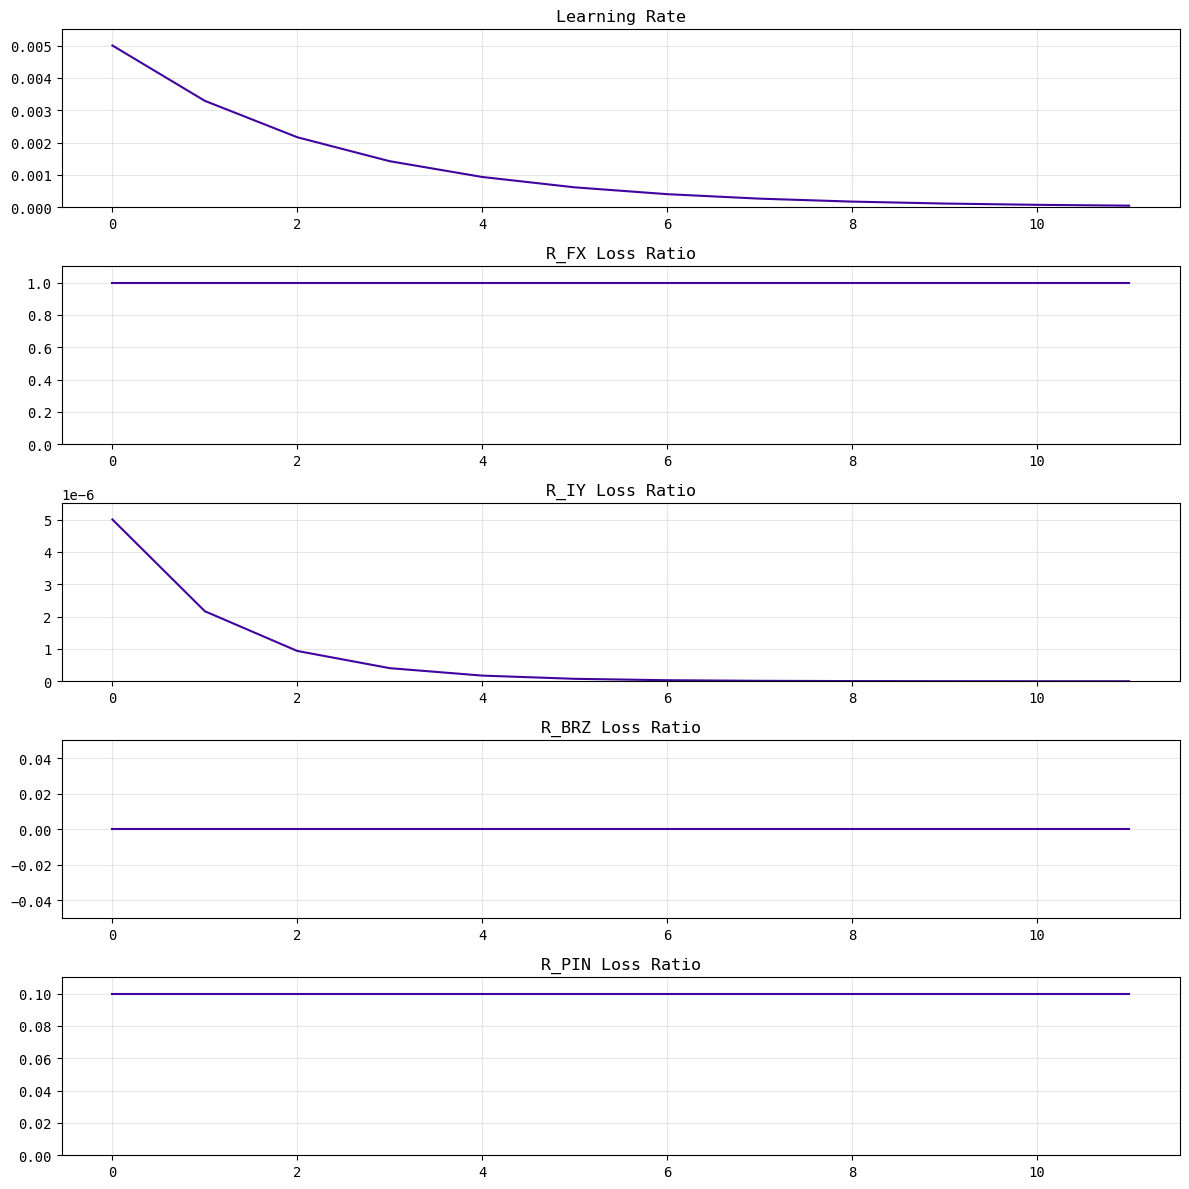

In [6]:
# plot schedulers
plt.figure(figsize=(12, 12))
plt.subplot(5, 1, 1) 
plt.plot(LR)
plt.ylim(0, np.max(LR)*1.1)
plt.title('Learning Rate')
plt.subplot(5, 1, 2)
plt.plot(R_FX)
plt.ylim(0, np.max(R_FX)*1.1)
plt.title('R_FX Loss Ratio')
plt.subplot(5, 1, 3)
plt.plot(R_IY)
plt.ylim(0, np.max(R_IY)*1.1)
plt.title('R_IY Loss Ratio')
plt.subplot(5, 1, 4)
plt.plot(R_BRZ)
plt.ylim(0, np.max(R_BRZ)*1.1)
plt.title('R_BRZ Loss Ratio')
plt.subplot(5, 1, 5)
plt.plot(R_PIN)
plt.ylim(0, np.max(R_PIN)*1.1)
plt.title('R_PIN Loss Ratio')
plt.tight_layout()
plt.show() if LOCAL else plt.savefig(f"{SAVE_DIR}/schedulers.png")

Dataset loaded from dss/train_ds.npz, keys: dict_keys(['phys', 'pts', 'Fx', 'Iy', 'Br', 'Bz'])
Dataset: n_t:1600, total_pts_per_t:500, picked:20 -> N:40000 (1600*500//20), memory:19.8144MB, on_dev:False
Dataset loaded from dss/eval_ds.npz, keys: dict_keys(['phys', 'pts', 'Fx', 'Iy', 'Br', 'Bz'])
Dataset: n_t:400, total_pts_per_t:500, picked:20 -> N:10000 (400*500//20), memory:4.9536MB, on_dev:False
test_dataset
Dataset length: 10000
Inputs: X -> torch.Size([96]), r -> torch.Size([20, 2]), z -> torch.Size([20])
Outputs: Y1 -> torch.Size([20]), Y2 -> torch.Size([20]), Y3 -> torch.Size([20])
10000


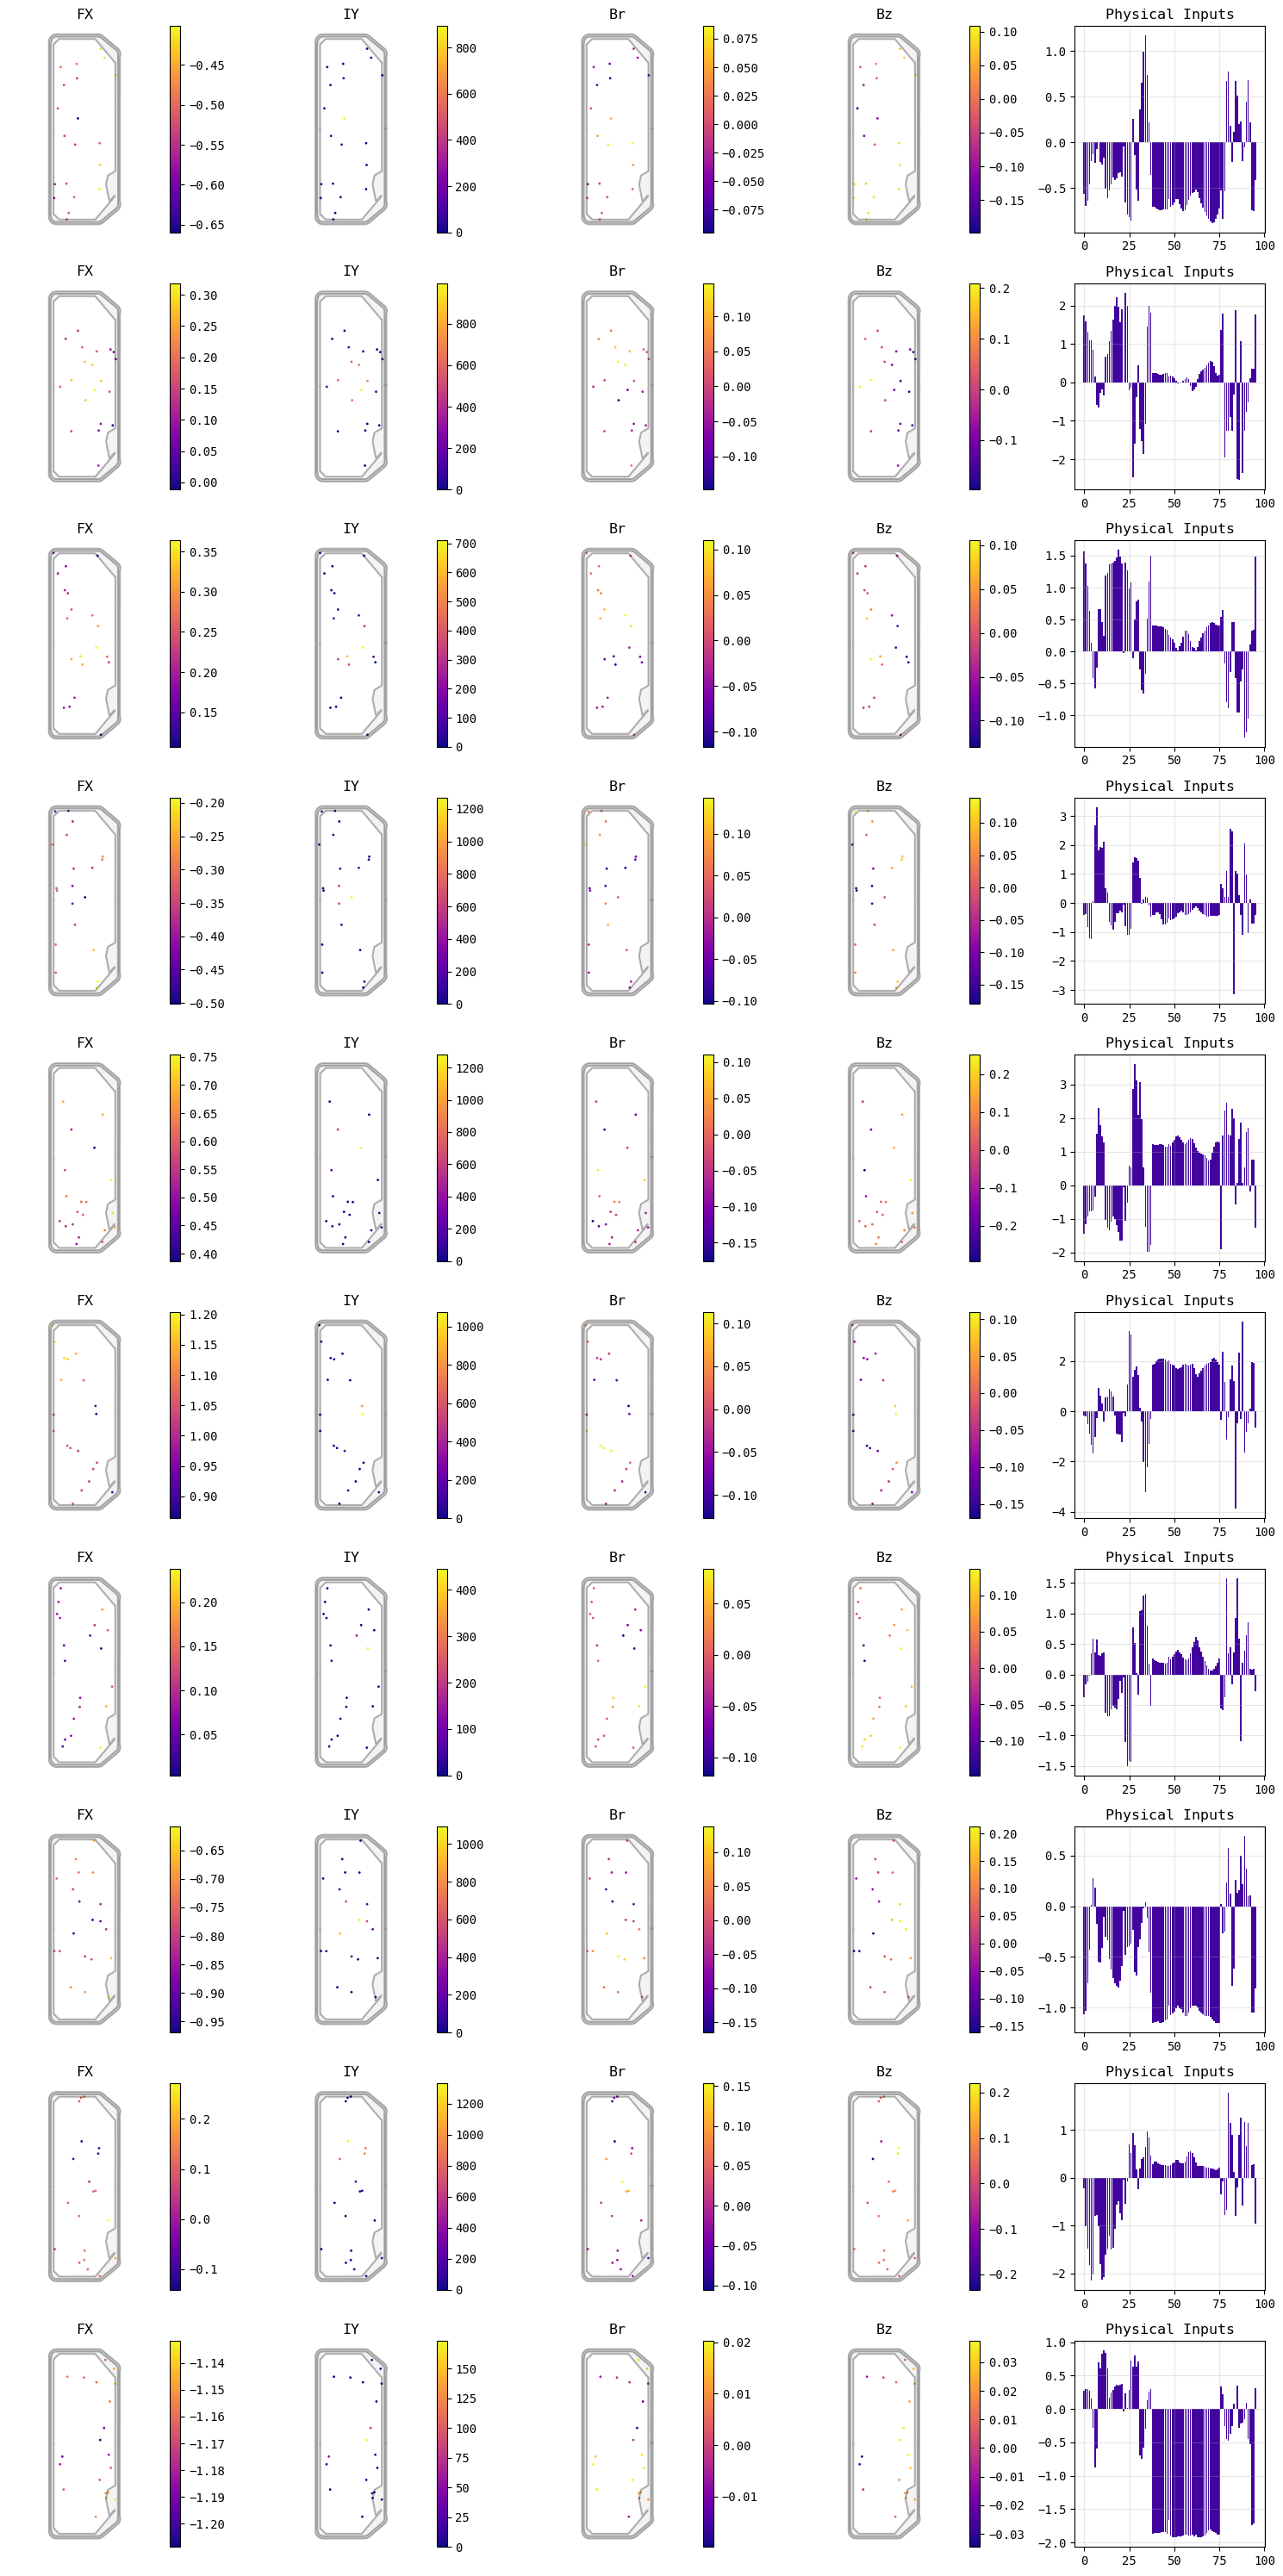

In [7]:
# create training and evaluation datasets
train_ds = LiuqeDataset(TRAIN_DS_PATH, pts_per_sample=PTS_PER_SAMPLE)
val_ds = LiuqeDataset(EVAL_DS_PATH, pts_per_sample=PTS_PER_SAMPLE)
test_dataset(val_ds)
#save the mean_std of the dataset int the save directory
np.savez(f"{SAVE_DIR}/x_mean_std.npz", x_mean_std=train_ds.x_mean_std.cpu().numpy())

## Training

In [8]:
def train():
    train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True) # initialize DataLoader
    val_dl = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False) # initialize DataLoader
    # network
    model = liuqeML(train_ds.x_mean_std)
    opt = torch.optim.Adam(model.parameters(), lr=LR[0])# adam
    # opt = torch.optim.AdamW(model.parameters(), lr=LR[0], weight_decay=1e-4) # adamw
    # opt = torch.optim.Muon(model.parameters(), lr=LR[0]) # Muon optimizer

    if LOAD_PRETRAINED is not None: # load pretrained model
        model.load_state_dict(torch.load(LOAD_PRETRAINED, map_location=torch.device(CPU)), strict=STRICT_LOAD) # load pretrained model
        print(f"Pretrained model loaded: {LOAD_PRETRAINED}")

    model.to(DEV) # move model to DEV
    loss_fn = F.mse_loss # Mean Squared Error
    # loss_fn = F.l1_loss # Mean Absolute Error
    tlog, elog = np.inf*np.ones((EPOCHS, len(train_dl), len(LOSS_NAMES))), np.inf*np.ones((EPOCHS, len(val_dl), len(LOSS_NAMES))) # init log
    start_time = time() # start time
    print("Ep:    || fx    | iy  | brz | brzp|| r:fx| r:iy|r:brz|r:pin| LR  || t  | eta| improved    ")
    for ep in range(EPOCHS): # epochs
        epoch_time = time()
        for pg in opt.param_groups: pg['lr'] = LR[ep] # update learning rate
        model.train()
        for ib, batch in enumerate(train_dl):
            if train_ds.on_dev: x, p, fx, iy, br, bz = batch # unpack batch
            else: x, p, fx, iy, br, bz = map(lambda t: t.to(DEV), batch) # move to DEV
            # PINN version
            r = p.clone()[:,:,0] # r coordinates
            p.requires_grad = True # enable gradients for p

            opt.zero_grad() # zero gradients
            fxp, brzp, iyp = model(x, p) # forward pass
            brp, bzp = brzp[:,:,0], brzp[:,:,1] # unpack into br and bz

            # calculate derivatives of Fx wrt r and z
            dFx_drz, = torch.autograd.grad(outputs=fxp.sum(), inputs=p, create_graph=True)
            dF_dr, dF_dz = dFx_drz[:,:,0], dFx_drz[:,:,1] # derivative of Fx wrt r and z
            Br_pinn = -dF_dz / (2 * torch.pi * r) # Br from derivative
            Bz_pinn = dF_dr / (2 * torch.pi * r) # Bz from derivative

            # losses
            l_fx = loss_fn(fx, fxp) # fx loss
            l_iy = loss_fn(iy, iyp) # iy loss
            l_brz = loss_fn(br, brp) + loss_fn(bz, bzp) # br bz loss
            l_brz_pinn = loss_fn(br, Br_pinn) + loss_fn(bz, Bz_pinn) # br bz loss from derivative

            loss = R_FX[ep]*l_fx + R_IY[ep]*l_iy + R_BRZ[ep]*l_brz + R_PIN[ep]*l_brz_pinn # total loss
            loss.backward() # backprop

            # torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0) # gradient clipping
            
            opt.step() # update weights

            # tlog[ep, ib] = (l_fx.item(), l_iy.item(), l_br.item(), l_bz.item(), l_br_pinn.item(), l_bz_pinn.item()) # save batch losses
            tlog[ep, ib] = (l_fx.item(), l_iy.item(), l_brz.item(), l_brz_pinn.item()) # save batch losses
        
        model.eval() # evaluation mode
        with torch.no_grad(): # Disable gradients for most of the validation
            for ib, batch in enumerate(val_dl):
                if val_ds.on_dev: x, p, fx, iy, br, bz = batch # unpack batch
                else: x, p, fx, iy, br, bz = map(lambda t: t.to(DEV), batch) # move to DEV

                # PINN version
                r = p.clone()[:,:,0] # r coordinates
                with torch.enable_grad():
                    p.requires_grad = True # enable gradients for p
                    fxp, brzp, iyp = model(x, p) # forward pass
                    brp, bzp = brzp[:,:,0], brzp[:,:,1] # unpack outputs
                    dFx_drz, = torch.autograd.grad(outputs=fxp.sum(), inputs=p)
                dF_dr, dF_dz = dFx_drz[:,:,0], dFx_drz[:,:,1] # derivative of Fx wrt r and z
                Br_pinn = -dF_dz / (2 * torch.pi * r) # Br from derivative
                Bz_pinn = dF_dr / (2 * torch.pi * r) # Bz from derivative

                # losses
                l_fx = loss_fn(fx, fxp) # fx loss
                l_iy = loss_fn(iy, iyp) # iy loss
                l_brz = loss_fn(br, brp) + loss_fn(bz, bzp) # br bz loss
                l_brz_pinn = loss_fn(br, Br_pinn) + loss_fn(bz, Bz_pinn) # br bz loss from derivative

                elog[ep, ib] = (l_fx.item(), l_iy.item(), l_brz.item(), l_brz_pinn.item())

        # save model if improved
        endp = ""
        epoch_losses = np.mean(elog[ep,:,:], axis=0) # epoch losses: mean across batchess
        best_losses = np.min(np.mean(elog[:ep,:,:], axis=1), axis=0) if ep > 0 else epoch_losses # best losses: min across epochs
        for el, bl, n in zip(epoch_losses, best_losses, LOSS_NAMES):
            if el <= bl: torch.save(model.state_dict(), model_path(n)); endp+=f"*{n}"
        # print progress
        print(f"{ep+1:03d}/{EPOCHS:02d}||" + f"{epoch_losses[0]:.1e}|" +
            '|'.join([f"{v:.0e}" for v in epoch_losses[1:]]) + "||" +
            f"{R_FX[ep]:.0e}|{R_IY[ep]:.0e}|{R_BRZ[ep]:.0e}|{R_PIN[ep]:.0e}|{LR[ep]:.0e}||" +
            f"{int(time()-epoch_time):03d}s|{int((time()-start_time)*(EPOCHS-ep)/(ep+1)/60):03d}m|", end=endp+'\n')
        # if ep >= 10 and best_losses[2] > 0.1: return False 

    tlosses, elosses = np.mean(tlog, axis=1), np.mean(elog, axis=1) # losses across epochs
    print(f"Training time: {(time()-start_time)/60:.0f}mins")
    print("Best MSE: " + ", ".join([f"{n} {bl:.3e} (ep {be})" for n, bl, be in zip(LOSS_NAMES, np.min(elosses, axis=0), np.argmin(elosses, axis=0))]))
    print("Estimated MAE: " + ", ".join([f"{n} {np.sqrt(np.min(np.mean(elog[:,:,i], axis=1))):.3e}" for i, n in enumerate(LOSS_NAMES)]))
    np.save(f"{SAVE_DIR}/train_losses.npy", tlosses) # save training losses
    np.save(f"{SAVE_DIR}/eval_losses.npy", elosses) # save evaluation losses
    return True

# train the model (multiple attempts)
for i in range(20): 
    print('Starting training...')
    success = train()
    if success: break
    else: print(f"Convergence failed, retrying... {i+1}/20")
# if not success: delete the files and exit:
if not success: os.system(f"rm -rf {SAVE_DIR}")
assert success, "Training failed, no model saved"

Starting training...
Ep:    || fx    | iy  | brz | brzp|| r:fx| r:iy|r:brz|r:pin| LR  || t  | eta| improved    
001/12||1.5e-03|6e+03|7e-01|3e-03||1e+00|5e-06|0e+00|1e-01|5e-03||009s|001m|*Fx*Iy*Brz*Brzp
002/12||7.1e-04|5e+03|6e-01|2e-03||1e+00|2e-06|0e+00|1e-01|3e-03||008s|001m|*Fx*Iy*Brz*Brzp
003/12||5.0e-04|4e+03|5e-01|1e-03||1e+00|9e-07|0e+00|1e-01|2e-03||008s|001m|*Fx*Iy*Brz*Brzp
004/12||4.5e-04|4e+03|5e-01|1e-03||1e+00|4e-07|0e+00|1e-01|1e-03||008s|001m|*Fx*Iy*Brz*Brzp
005/12||3.3e-04|4e+03|5e-01|1e-03||1e+00|2e-07|0e+00|1e-01|9e-04||007s|001m|*Fx*Iy*Brz*Brzp
006/12||3.0e-04|4e+03|5e-01|1e-03||1e+00|8e-08|0e+00|1e-01|6e-04||008s|000m|*Fx*Brz*Brzp
007/12||2.7e-04|4e+03|5e-01|1e-03||1e+00|3e-08|0e+00|1e-01|4e-04||007s|000m|*Fx*Brz*Brzp
008/12||2.6e-04|4e+03|5e-01|9e-04||1e+00|1e-08|0e+00|1e-01|3e-04||007s|000m|*Fx*Brz*Brzp
009/12||2.4e-04|4e+03|5e-01|9e-04||1e+00|6e-09|0e+00|1e-01|2e-04||007s|000m|*Fx*Brz*Brzp
010/12||2.4e-04|4e+03|5e-01|9e-04||1e+00|3e-09|0e+00|1e-01|1e-04||007s|0

Plotting losses...


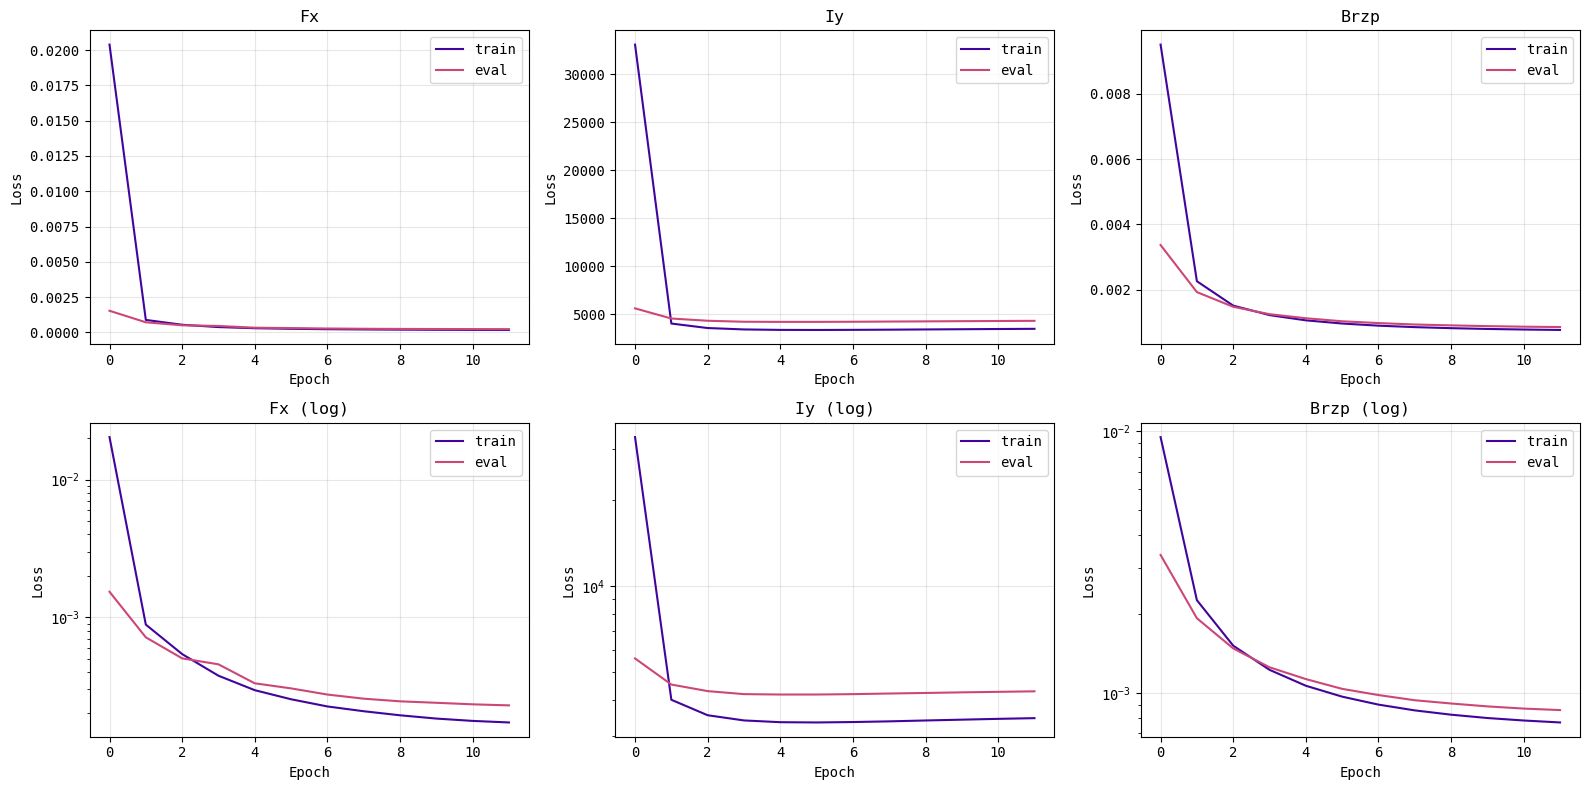

In [9]:
# plot losses
print("Plotting losses...")
# fig, ax = plt.subplots(2, len(LOSS_NAMES), figsize=(4*len(LOSS_NAMES), 8))
fig = plt.figure(figsize=(4*len(LOSS_NAMES), 8))
# Load losses
train_loss = np.load(f"{SAVE_DIR}/train_losses.npy")
eval_loss = np.load(f"{SAVE_DIR}/eval_losses.npy")
n_active_losses = sum(ACTIVE_LOSSES)
active_names = [name for i, name in enumerate(LOSS_NAMES) if ACTIVE_LOSSES[i]]
active_indices = [i for i, active in enumerate(ACTIVE_LOSSES) if active]
for i, name in enumerate(active_names):
    # Linear scale
    plt.subplot(2, n_active_losses, i+1)
    plt.plot(train_loss[:,active_indices[i]], label='train')
    plt.plot(eval_loss[:,active_indices[i]], label='eval')
    plt.title(f"{name}")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    # Log scale
    plt.subplot(2, n_active_losses, i+1 + n_active_losses)
    plt.plot(train_loss[:,active_indices[i]], label='train')
    plt.plot(eval_loss[:,active_indices[i]], label='eval')
    plt.yscale('log')
    plt.title(f"{name} (log)")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
plt.tight_layout()
plt.show() if LOCAL else plt.savefig(f"{SAVE_DIR}/losses.png")

In [10]:
## TODO: complete this
# def plot_network_outputs(ds:LiuqeDataset, model:liuqeML, title="test", save_dir=SAVE_DIR, nplt=2 if LOCAL else 50, pinn=True):
#     assert ds.fg is not None, "Dataset does not have full grid data (fg)"
#     _ds_pps = ds.pps # tmp workaround for proper plotting
#     ds.pps = ds.tnp # make ds to sample every point for every timestamp
#     main_col = 'w' if DARK_THEME else 'k'
#     if not pinn: model.eval()
#     model.to(CPU)
#     os.makedirs(f"{save_dir}/imgs", exist_ok=True)
#     for pi, i in enumerate(np.random.randint(0, len(ds), nplt)):  
#         on_grid = pi >= (nplt // 2) # on grid or not
#         if not on_grid: continue # tmp
#         fs = (20, 8) if on_grid else (15, 8) # figure size
#         plt.figure(figsize=fs, facecolor='white' if DARK_THEME else 'black')
#         x, p, fx, iy, br, bz = ds[i]
#         x, p, fx, iy, br, bz = map(lambda x: x.to(CPU), [x, p, fx, iy, br, bz])
#         if on_grid: 
#             p = torch.stack([torch.tensor(RRD.reshape(-1), dtype=torch.float32), torch.tensor(ZZD.reshape(-1), dtype=torch.float32)], dim=1)  # shape (n, 2)
#             fx, iy, br, bz = [to_tensor(v.reshape(-1)) for v in ds.fg[i]] # reshape to (n,)
#         if pinn: r = p.clone()[:,0]; p.requires_grad = True # need r for PINN
#         fxp, brzp, iyp = model(x.unsqueeze(0), p.unsqueeze(0))
#         if pinn:
#             print(f'fxp: {fxp.shape}, p: {p.shape}')
#             dFx_drz = torch.autograd.grad(outputs=fxp.sum(), inputs=p, create_graph=True)[0].unsqueeze(0) # compute gradients wrt p
#             print(f'dFx_drz: {dFx_drz.shape}')
#             dF_dr, dF_dz = dFx_drz[:,:,0], dFx_drz[:,:,1]  # shape (1, n)
#             brp = -dF_dz / (2 * torch.pi * r) # Br from derivative
#             bzp = dF_dr / (2 * torch.pi * r)  # Bz from derivative
#             print(f'brp, bzp: {brp.shape}, {bzp.shape}')
#             # calculate second derivative
#             ddFx_ddrz = torch.autograd.grad(outputs=dFx_drz.sum(), inputs=p, create_graph=True)[0].unsqueeze(0)
#             ddF_ddr2, ddF_ddz2 = ddFx_ddrz[:,:,0], ddFx_ddrz[:,:,1]
#             μ0 = 4e-7 * np.pi  # Permeability of free space
#             # brp, bzp = (ddFx_ddrz[:,:,0]+ddFx_ddrz[:,:,1])/(μ0*2*np.pi*r), (ddFx_ddrz[:,:,0]-ddFx_ddrz[:,:,1])/(μ0*2*np.pi*r)
#             J = (1 / (2 * torch.pi * μ0 * r)) * (ddF_ddr2 - (1/r) * dF_dr + ddF_ddz2) # best so far
#             # J = -(1 / (2 * torch.pi * μ0 * r)) * (ddF_ddz2 - (1/r) * dF_dr + ddF_ddr2) # mmm
#             brp, bzp = J, J
#         else: brp, bzp = brzp[:,:,0], brzp[:,:,1]  # split Br, Bz
#         fxp, iyp, brp, bzp = map(lambda t: t.squeeze(0), [fxp, iyp, brp, bzp]) # remove batch dimension
#         p, fx, iy, br, bz, fxp, iyp, brp, bzp = map(lambda t: t.detach().cpu().numpy(), [p, fx, iy, br, bz, fxp, iyp, brp, bzp]) # move to CPU and numpy
#         iy = np.abs(iy)  # ensure current density is positive
#         iv = inpoly(p) # inside vessel indices
#         mfx, Mfx = np.min([fx[iv], fxp[iv]]), np.max([fx[iv], fxp[iv]])
#         miy, Miy = np.min([iy[iv], iyp[iv]]), np.max([iy[iv], iyp[iv]])
#         mbr, Mbr = np.min([br[iv], brp[iv]]), np.max([br[iv], brp[iv]])
#         mbz, Mbz = np.min([bz[iv], bzp[iv]]), np.max([bz[iv], bzp[iv]])
#         lw, col, ms = 1.5, 'gray', 4
#         limits = [(mfx, Mfx), (miy, Miy), (mbr, Mbr), (mbz, Mbz)] # variable limits
#         vals = [(fx, fxp), (iy, iyp), (br, brp), (bz, bzp)]
#         names = ["Fx", "Iy", "Brp" if pinn else "Br", "Bzp" if pinn else "Bz"]
#         def prep_plot(ax):
#             ax.grid(False)
#             ax.set_xticks([])
#             ax.set_yticks([])
#             ax.set_aspect("equal")
#             ax.spines['top'].set_visible(False)
#             ax.spines['right'].set_visible(False)
#             ax.spines['left'].set_visible(False)
#             ax.spines['bottom'].set_visible(False)
#             plot_vessel(ax) # plot vessel
#         nraws = 2
#         ncols = 8 if on_grid else 6 # number of columns
#         α_sep = 0.5
#         for j, ((v, vp), l, n) in enumerate(zip(vals, limits, names)):
#             plt.subplot(nraws, ncols, j*(ncols//2)+1), plt.title(f"{n} Actual")
#             plt.scatter(p[iv,0], p[iv,1], c=v[iv], s=ms, vmin=l[0], vmax=l[1])
#             prep_plot(plt.gca()), plt.colorbar()
#             plt.subplot(nraws, ncols, j*(ncols//2) + 2), plt.title(f"{n} Predicted")
#             plt.scatter(p[iv,0], p[iv,1], c=vp[iv], s=ms, vmin=l[0], vmax=l[1])
#             prep_plot(plt.gca()), plt.colorbar()
#             plt.subplot(nraws, ncols, j*(ncols//2) + ncols//2), plt.title(f"{n} Error %")
#             ep = 100*np.abs(v[iv]-vp[iv])/(l[1]-l[0]) # error in %
#             # plt.scatter(p[iv,0], p[iv,1], c=ep, s=ms, vmin=0, vmax=np.max(ep)) # variable bar
#             plt.scatter(p[iv,0], p[iv,1], c=ep, s=ms, vmin=0, vmax=np.max(ep) if n == IY else 1.0) # fixed bar
#             # plt.scatter(p[iv,0], p[iv,1], c=ep, s=ms, vmin=0, vmax=np.max(ep)) # variable bar
#             prep_plot(plt.gca()), plt.colorbar()
#             if on_grid: # plot contours if on grid
#                 plt.subplot(nraws, ncols, j*(ncols//2) + 3), plt.title(f"{n} Contours")
#                 plt.contour(RRD, ZZD, v.reshape(65,28), levels=20, linestyles='solid')
#                 plt.contour(RRD, ZZD, vp.reshape(65,28), levels=20, linestyles='dashed')
#                 prep_plot(plt.gca()), plt.colorbar()
#         fig = plt.gcf() # Get the current figure
#         dx, xoff = 0.004, 0.01 #0.005, 0.008
#         # dy, yoff = dx*fs[0]/fs[1], -0.012 #dx*fs[0]/fs[1], 0.003
#         dy, yoff = dx*fs[0]/fs[1], -0.018 #dx*fs[0]/fs[1], 0.003
#         tvs = 0.041 # title verticale space
#         from matplotlib.patches import Rectangle
#         # for x0, y0, lx, ly in [(0.0+dx, 0.5+dy/2+yoff, (1-3*dx)/2+xoff, (1-3*dy)/2-yoff-tvs),
#         #                        (0.5+dx/2+xoff, 0.5+dy/2+yoff, (1-3*dx)/2-xoff, (1-3*dy)/2-yoff-tvs),
#         #                        (0.0+dx, 0.0+dy, (1-3*dx)/2+xoff, (1-3*dy)/2+yoff),
#         #                        (0.5+dx/2+xoff, 0.0+dy, (1-3*dx)/2-xoff, (1-3*dy)/2+yoff)]:
#         for x0, y0, lx, ly in [(0.0+dx,         0.5+dy/2+yoff, (1-3*dx)/2+xoff, (1-3*dy)/2-yoff-tvs),
#                                (0.5+dx/2+xoff,  0.5+dy/2+yoff, (1-3*dx)/2-xoff, (1-3*dy)/2-yoff-tvs),
#                                (0.0+dx,         0.0+dy, (1-3*dx)/2+xoff, (1-3*dy)/2+yoff),
#                                (0.5+dx/2+xoff,  0.0+dy, (1-3*dx)/2-xoff, (1-3*dy)/2+yoff)]:
#             fig.patches.append(Rectangle( (x0, y0), lx, ly, transform=fig.transFigure, color='black' if DARK_THEME else 'white', alpha=1, zorder=-1))
#         plt.suptitle(f"[{JOBID}] liuqeML: {title} {i}", y=0.985, color='black' if DARK_THEME else 'white')
#         plt.tight_layout()
#         plt.savefig(f"{save_dir}/imgs/net_example_{'g_' if on_grid else ''}{title}_{i}.png")
#         if LOCAL: plt.show()  
#         plt.close()
#     ds.pps = _ds_pps # restore dataset pps
#     return


Testing network output...


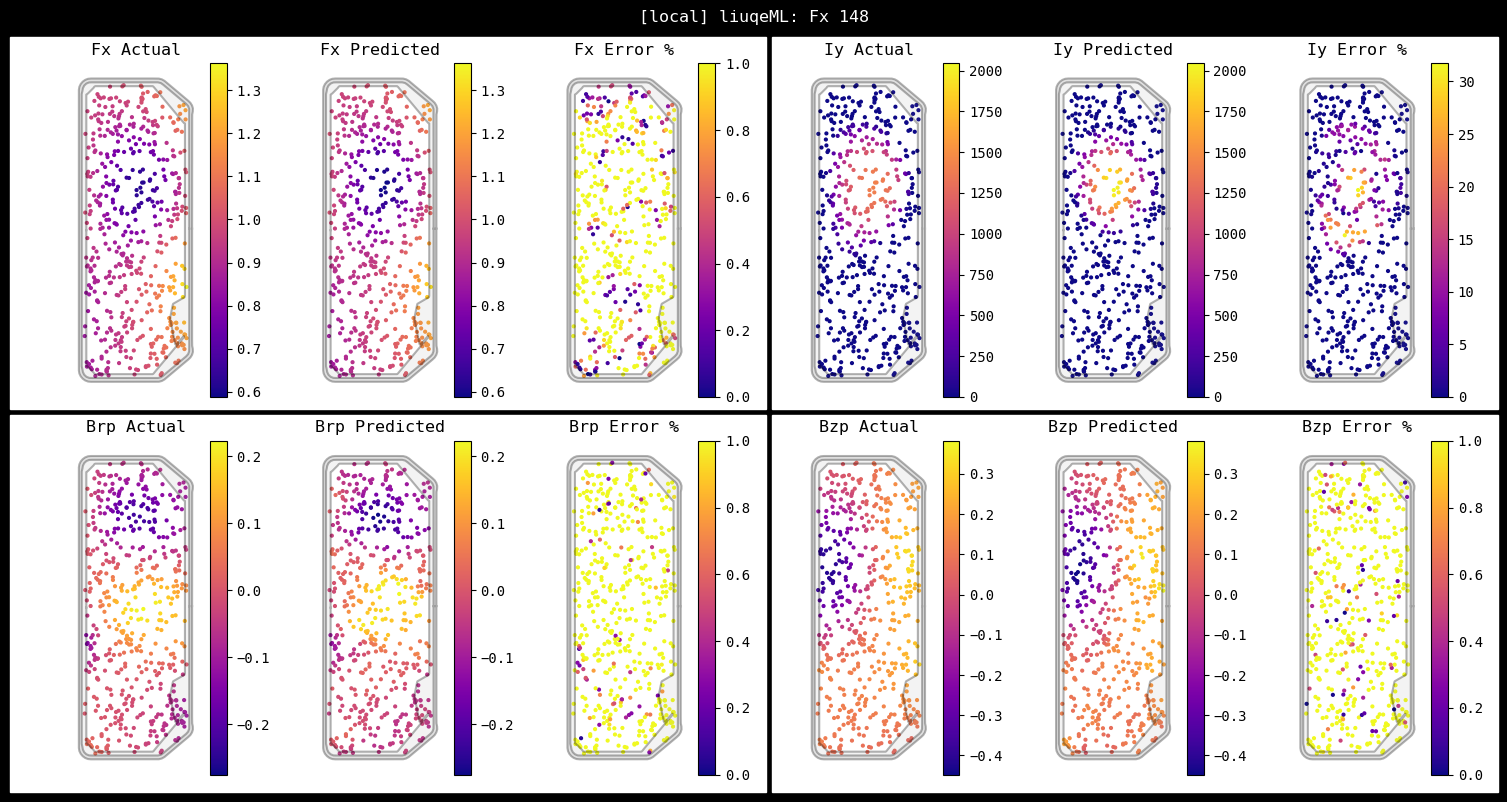

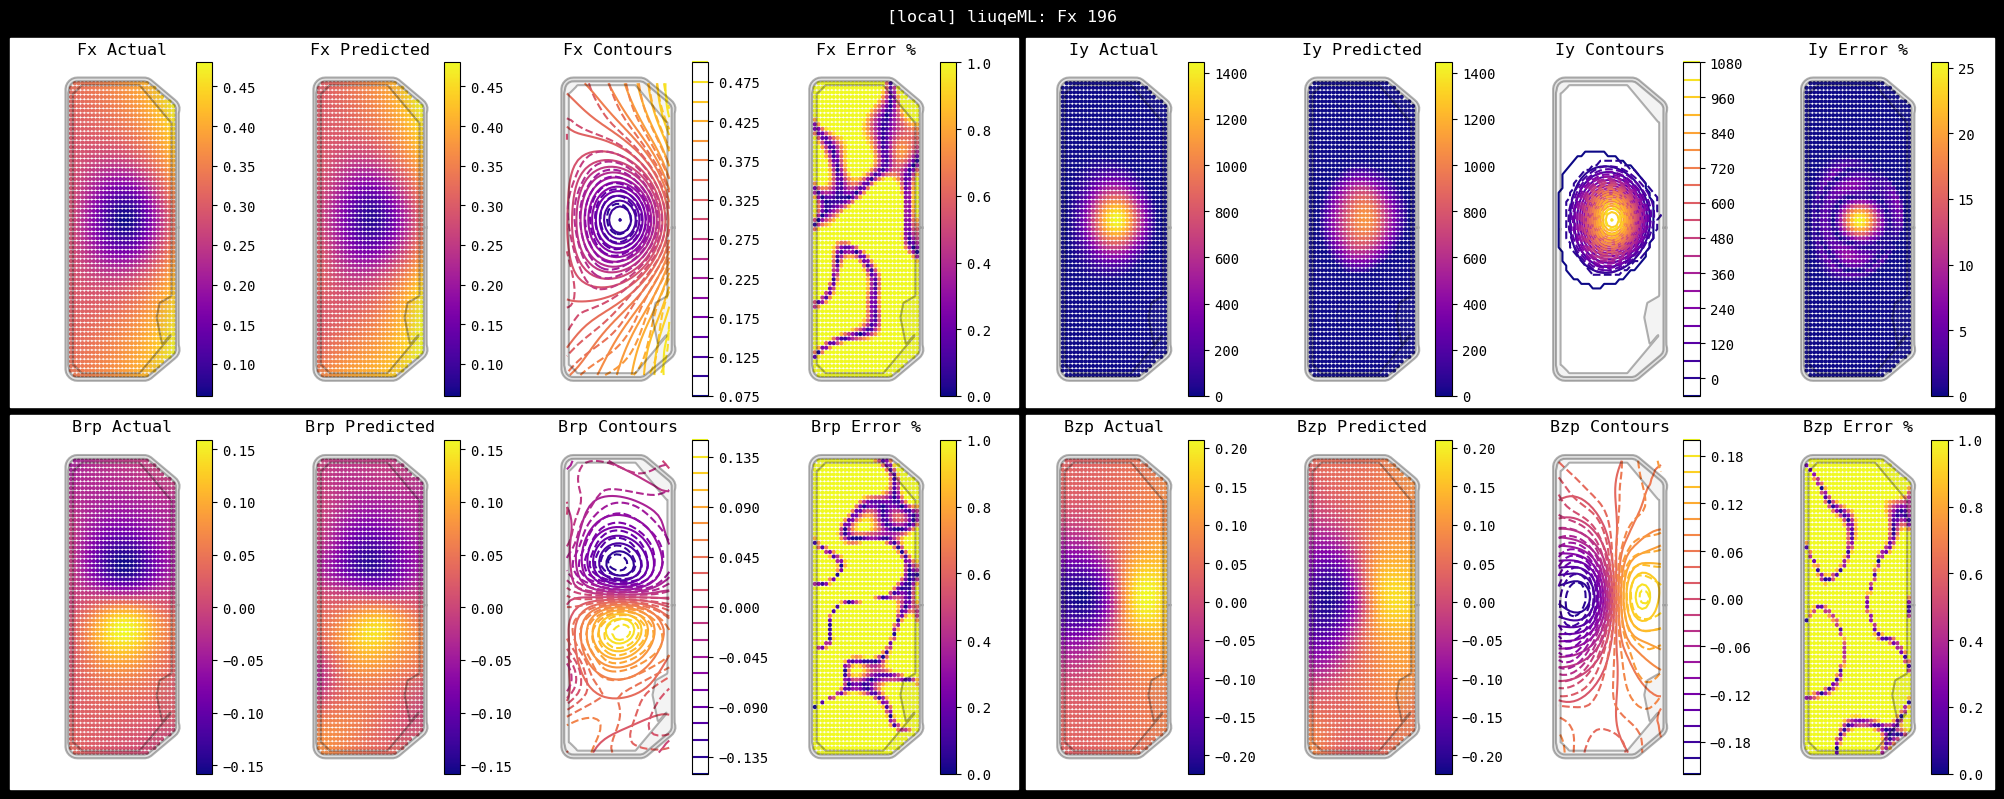

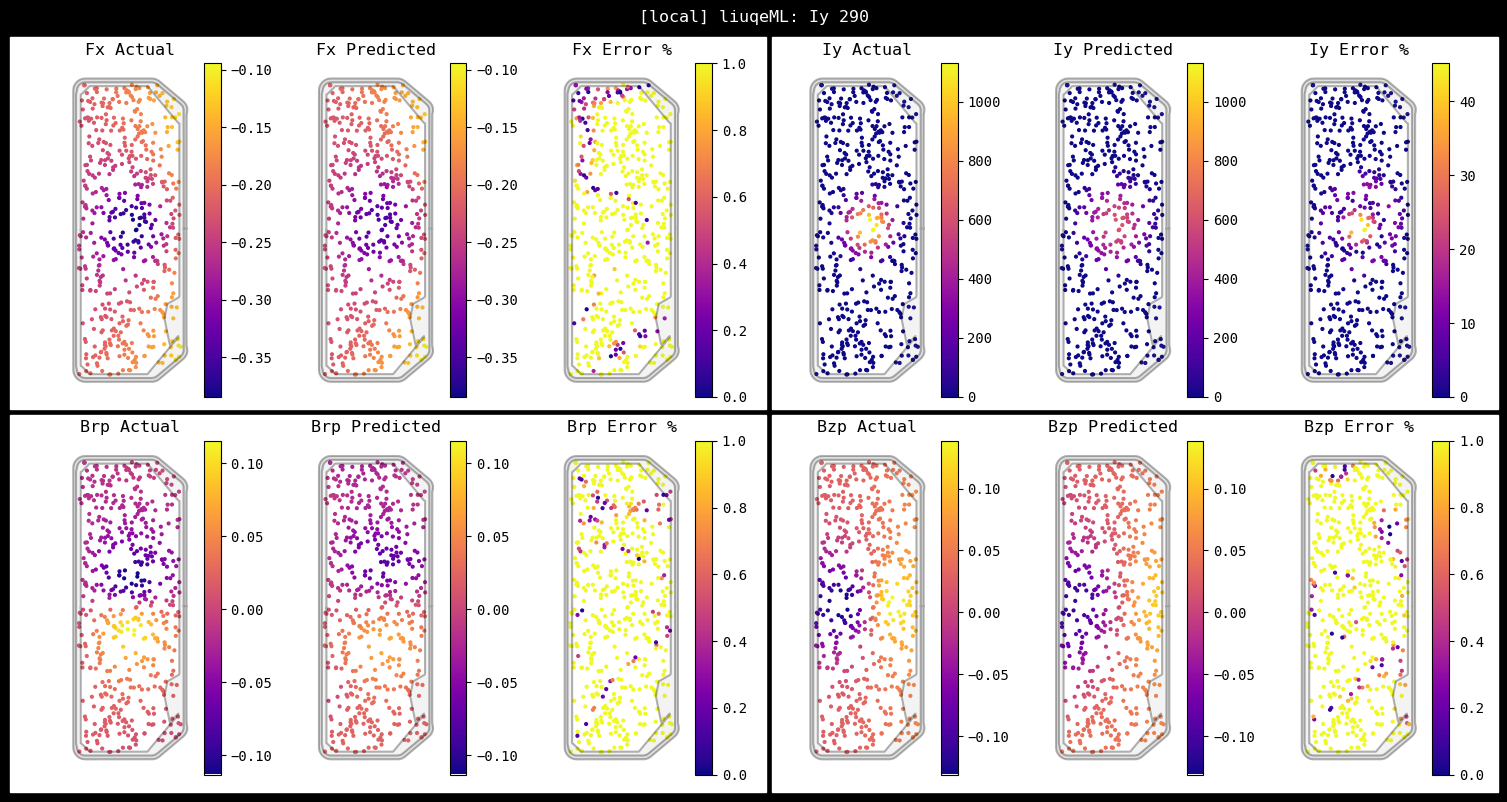

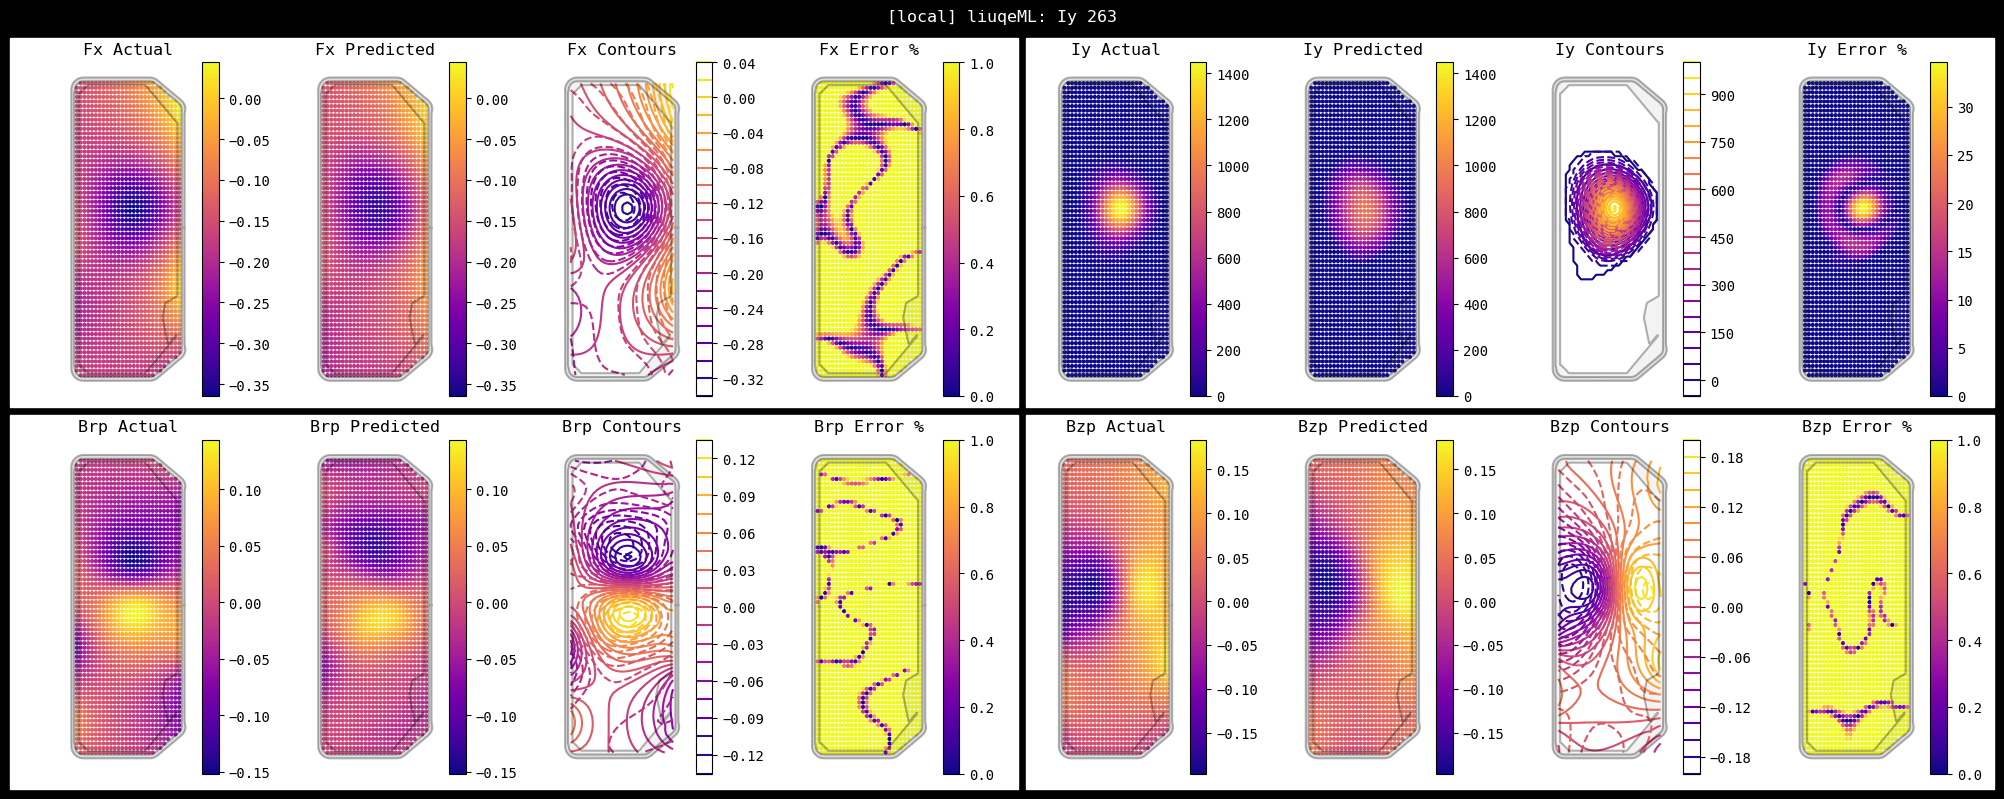

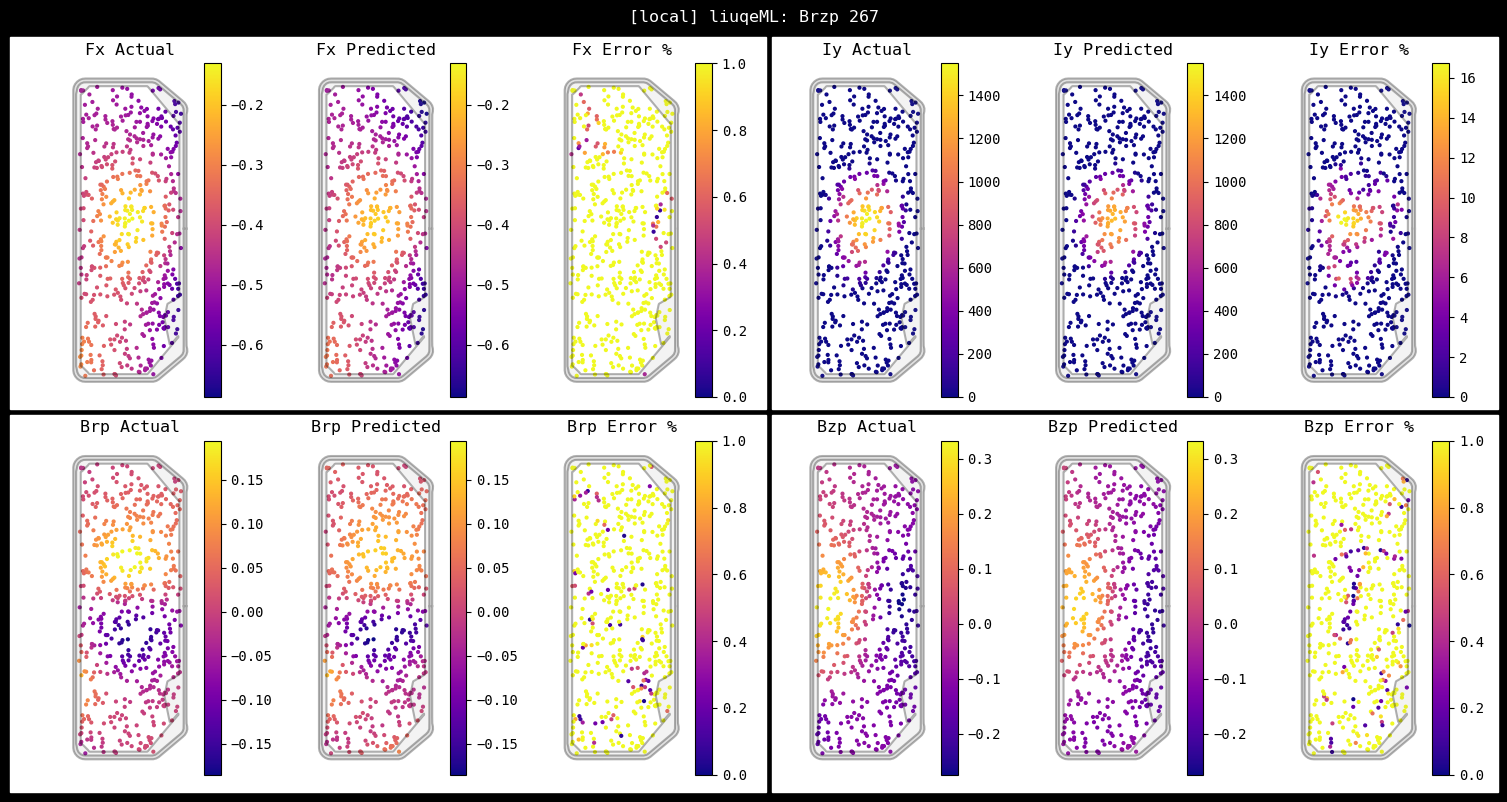

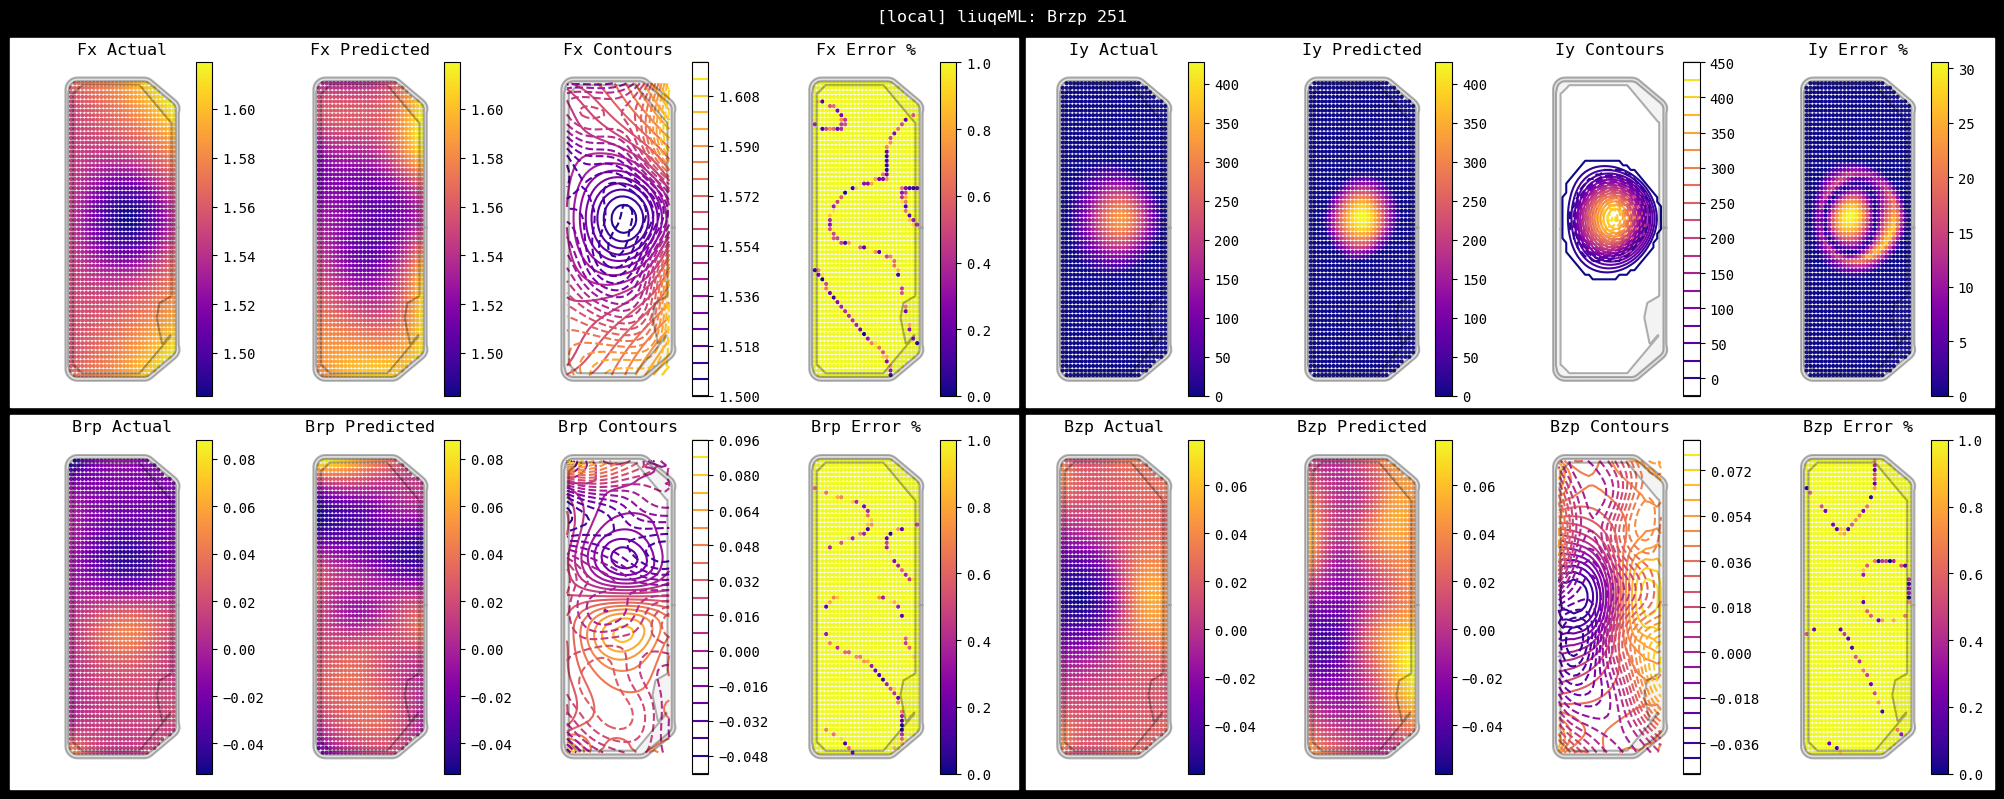

In [11]:
# testing network outputs
# try:
if True:
    print("Testing network output...")
    for active, ln in zip(ACTIVE_LOSSES, LOSS_NAMES):
        if not active: continue
        model = liuqeML(train_ds.x_mean_std)
        model.load_state_dict(torch.load(model_path(ln), map_location=torch.device(CPU))) # load pretrained model
        plot_network_outputs(val_ds, model, title=ln, pinn=R_PIN[-1]>R_BRZ[-1]) # plot network outputs
# except Exception as e:
#     print(f"Error in testing network output: {e}")
#     print("Skipping network output testing...")
#     pass

In [12]:
# save weights to .mat file
m = liuqeML(train_ds.x_mean_std)
for active, ln in zip(ACTIVE_LOSSES, LOSS_NAMES):
    if active:
        m.load_state_dict(torch.load(model_path(ln), map_location=torch.device(CPU))) # load pretrained model
        save_weights_to_mat(m, title=ln)

Weights Fx: dict_keys(['x_mean_std', 'pts_enc_0_weight', 'pts_enc_0_bias', 'pts_enc_1_beta', 'pts_enc_2_weight', 'pts_enc_2_bias', 'pts_enc_3_beta', 'phys_enc_0_weight', 'phys_enc_0_bias', 'phys_enc_1_beta', 'phys_enc_2_weight', 'phys_enc_2_bias', 'phys_enc_3_beta', 'fx_head_0_weight', 'fx_head_0_bias', 'fx_head_1_beta', 'fx_head_2_weight', 'fx_head_2_bias', 'fx_head_3_beta', 'brz_head_0_weight', 'brz_head_0_bias', 'brz_head_1_beta', 'brz_head_2_weight', 'brz_head_2_bias', 'brz_head_3_beta', 'iy_head_0_weight', 'iy_head_0_bias', 'iy_head_1_beta', 'iy_head_2_weight', 'iy_head_2_bias', 'iy_head_3_beta'])
Weights saved to data/local/weights_Fx.mat
Weights Iy: dict_keys(['x_mean_std', 'pts_enc_0_weight', 'pts_enc_0_bias', 'pts_enc_1_beta', 'pts_enc_2_weight', 'pts_enc_2_bias', 'pts_enc_3_beta', 'phys_enc_0_weight', 'phys_enc_0_bias', 'phys_enc_1_beta', 'phys_enc_2_weight', 'phys_enc_2_bias', 'phys_enc_3_beta', 'fx_head_0_weight', 'fx_head_0_bias', 'fx_head_1_beta', 'fx_head_2_weight', 'fx_

In [13]:
print(f"{JOBID} done")
if not LOCAL: sleep(30) # wait for files to update (for cluster)
#copy the log file to the folder
os.system(f"cp jobs/{JOBID}.txt {SAVE_DIR}/log.txt")

local done


cp: cannot stat 'jobs/local.txt': No such file or directory


256